# NLP in practice with spaCy and scikit-learn

This lesson is the practical side of the previous one. We prepare texts with **spaCy** (tokens, lemmas, stop words, parts of speech), turn them into numbers with **scikit-learn** (`CountVectorizer`, `TfidfVectorizer`), and draw word clouds.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import plotly.express as px
import spacy
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from spacy import displacy
from spacy.lang.en.stop_words import STOP_WORDS
from wordcloud import WordCloud

import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

## spaCy and its language models 🚀

[spaCy](https://spacy.io/) is a library built to take a text all the way from preprocessing to a model in production. Here we only use its preprocessing part.

Each language has its own rules (how to cut words, which words are stop words, how to find a lemma), so spaCy has one **model** per language: English, French, German, Spanish, Chinese and [many others](https://spacy.io/models). A model is installed once, in a terminal:

```
python -m spacy download en_core_web_sm    # small English model
python -m spacy download fr_core_news_sm   # small French model (used in the exercise)
```

Then it is loaded with `spacy.load`.

In [ ]:
nlp = spacy.load("en_core_web_sm")
print(nlp.pipe_names)

['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


**What this shows:** the English model is a chain of 6 components: `tok2vec` (turns the words into vectors used by the other components), `tagger` (parts of speech), `parser` (grammar of the sentences), `attribute_ruler`, `lemmatizer` (lemmas) and `ner` (named entities: people, places, dates…). They all run each time we call `nlp(text)`.

## The `Doc` object 📄

Calling `nlp(text)` runs the whole pipeline and returns a `Doc`: a sequence of `Token` objects. Each token carries many attributes. The ones we use most:

| attribute | meaning |
|---|---|
| `text` | the token as written |
| `lemma_` | its lemma (dictionary form) |
| `pos_` | its part of speech: noun, verb, adjective… |
| `is_stop` | is it a stop word? |
| `is_alpha` | is it made of letters only? |
| `is_punct` | is it a punctuation mark? |
| `like_num` | does it look like a number ("24", "ten")? |

#### See it with data 🔬: every token of a sentence

In [ ]:
doc = nlp("Hello World! Don't do this. I am Superman, wherever you are in the world, 24 hours a day.")

pd.DataFrame(
    [(t.text, t.lemma_, t.pos_, t.is_stop, t.is_alpha, t.is_punct, t.like_num) for t in doc],
    columns=["text", "lemma_", "pos_", "is_stop", "is_alpha", "is_punct", "like_num"],
)

,text,lemma_,pos_,is_stop,is_alpha,is_punct,like_num
0,Hello,hello,INTJ,False,True,False,False
1,World,World,PROPN,False,True,False,False
2,!,!,PUNCT,False,False,True,False
3,Do,do,AUX,True,True,False,False
4,n't,not,PART,True,False,False,False
5,do,do,VERB,True,True,False,False
6,this,this,PRON,True,True,False,False
7,.,.,PUNCT,False,False,True,False
8,I,I,PRON,True,True,False,False
9,am,be,AUX,True,True,False,False


**What this shows:** the sentence gives 24 tokens. The lemmas group the forms of a word: "am" and "are" → "be", "hours" → "hour", "n't" → "not". "World" and "Superman" are proper nouns (`PROPN`) and keep their capital letter in the lemma. The stop words ("Do", "this", "I", "you", "the"…) have `is_stop=True`, the punctuation marks have `is_punct=True`, and "24" is the only token with `like_num=True`. Note that "n't" is not `is_alpha`, because of its apostrophe.

### Parts of speech

The `pos_` attribute gives the grammatical role of each token. `spacy.explain` translates the short codes.

In [ ]:
for tag in ["NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV", "PRON", "DET", "ADP", "NUM", "PUNCT"]:
    print(f"{tag:6} {spacy.explain(tag)}")

NOUN   noun
PROPN  proper noun
VERB   verb
AUX    auxiliary
ADJ    adjective
ADV    adverb
PRON   pronoun
DET    determiner
ADP    adposition
NUM    numeral
PUNCT  punctuation


The parts of speech are useful to filter words: to find the subject of a text, the nouns and the proper nouns often say more than the verbs.

### Sentences and the dependency tree

spaCy also cuts the text into sentences (`doc.sents`) and analyses the grammar of each sentence. Its `displacy` tool draws the result: each arrow goes from a word to a word that depends on it. This is the modern version of the parse tree of the previous lesson.

In [ ]:
print([sentence.text for sentence in doc.sents])

displacy.render(nlp("The cat eats the fish."), style="dep", jupyter=True, options={"distance": 100})

['Hello World!', "Don't do this.", 'I am Superman, wherever you are in the world, 24 hours a day.']


**What this shows:** spaCy found the 3 sentences. In the tree, "eats" is the root of the sentence; "cat" is its subject (`nsubj`) and "fish" its direct object (`dobj`); each "the" is a determiner (`det`) attached to its noun. It is the same structure as the parse tree of the previous lesson, drawn in another way.

## Stop words ⛔

spaCy has a list of stop words for each language. It is a Python `set`, so you can extend it with your own words with the `|` operator (the union of two sets).

In [ ]:
print(f"{len(STOP_WORDS)} English stop words, for example: {sorted(STOP_WORDS)[:15]}")

my_stop_words = STOP_WORDS | {"hello", "superman"}
print(f"{len(my_stop_words)} words after adding 2 of our own")

326 English stop words, for example: ["'d", "'ll", "'m", "'re", "'s", "'ve", 'a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all']
328 words after adding 2 of our own


## A cleaning function 🧽

Let's put the pipeline of the previous lesson in one function. For each token, we keep its lemma in lower case if it is made of letters only (no punctuation, no numbers) and if it is not a stop word. Optionally, we keep only some parts of speech.

In [ ]:
def clean_text(doc, stop_words=STOP_WORDS, keep_pos=None):
    """Return the lemmas of a spaCy Doc, in lower case, without punctuation, numbers and stop words."""
    lemmas = []
    for token in doc:
        lemma = token.lemma_.lower()
        if not token.is_alpha or token.is_stop or lemma in stop_words:
            continue
        if keep_pos is not None and token.pos_ not in keep_pos:
            continue
        lemmas.append(lemma)
    return " ".join(lemmas)

print(doc.text)
print("cleaned:                ", clean_text(doc))
print("with our stop words:    ", clean_text(doc, stop_words=my_stop_words))
print("nouns and proper nouns: ", clean_text(doc, keep_pos={"NOUN", "PROPN"}))

Hello World! Don't do this. I am Superman, wherever you are in the world, 24 hours a day.
cleaned:                 hello world superman world hour day
with our stop words:     world world hour day
nouns and proper nouns:  world superman world hour day


**What this shows:** the 24 tokens become 6 lemmas, "hello world superman world hour day": the subject of the sentence in a few words. With our two extra stop words, "hello" and "superman" disappear too. Keeping only the nouns and proper nouns drops "hello", an interjection.

## A small corpus 💌

A **corpus** is a collection of documents. Here is a small one: twelve short texts about three subjects, space, cooking and football. (We keep the subject in a column, but we will not give it to any algorithm: it is only there to check the results.)

`nlp.pipe` processes many texts at once, faster than calling `nlp` on each text in a loop.

In [ ]:
corpus = pd.DataFrame({
    "subject": ["space"] * 4 + ["cooking"] * 4 + ["football"] * 4,
    "text": [
        "The rocket was launched from the space station and reached the orbit of Mars. The astronauts watched the red planet.",
        "Astronauts live on the space station for six months. They study the planets and the stars.",
        "A new telescope took pictures of a distant planet orbiting a young star. The space agency published the pictures.",
        "The mission to the Moon will send four astronauts and a small rover. The rocket will leave the station in May.",
        "Cook the pasta in boiling water and add the tomato sauce at the end. Serve with fresh basil.",
        "This soup is made with fresh vegetables, garlic and a little olive oil. Cook it slowly for one hour.",
        "Bake the cake for forty minutes and let it cool. Add the chocolate sauce before serving.",
        "The chef cooked a delicious sauce with tomatoes, garlic and fresh herbs. The pasta was perfect.",
        "The team scored two goals in the second half and won the match. The players thanked the fans.",
        "The goalkeeper stopped a penalty in the last minute of the game. His team won the match.",
        "The coach chose a young player to replace the injured striker. The team needs a goal.",
        "Fans sang in the stadium while the players celebrated the victory of their team.",
    ],
})
corpus["clean"] = [clean_text(d) for d in nlp.pipe(corpus["text"])]
corpus

,subject,text,clean
0,space,The rocket was launched from the space station...,rocket launch space station reach orbit mars a...
1,space,Astronauts live on the space station for six m...,astronaut live space station month study plane...
2,space,A new telescope took pictures of a distant pla...,new telescope picture distant planet orbit you...
3,space,The mission to the Moon will send four astrona...,mission moon send astronaut small rover rocket...
4,cooking,Cook the pasta in boiling water and add the to...,cook pasta boiling water add tomato sauce end ...
5,cooking,"This soup is made with fresh vegetables, garli...",soup fresh vegetable garlic little olive oil c...
6,cooking,Bake the cake for forty minutes and let it coo...,bake cake minute let cool add chocolate sauce ...
7,cooking,The chef cooked a delicious sauce with tomatoe...,chef cook delicious sauce tomato garlic fresh ...
8,football,The team scored two goals in the second half a...,team score goal second half win match player t...
9,football,The goalkeeper stopped a penalty in the last m...,goalkeeper stop penalty minute game team win m...


**What this shows:** each text is now a short list of lemmas, in lower case: "launched" → "launch", "astronauts" → "astronaut", "cooked" → "cook", "injured" → "injure". All the stop words and the punctuation are gone.

## Bag of words with `CountVectorizer` 🧮

`CountVectorizer` learns the vocabulary with `fit`, and counts the words of each document with `transform` (or both at once with `fit_transform`). It returns a **sparse matrix**.

A real corpus has tens of thousands of different words, and each document uses only a few of them: the document-term matrix is almost full of zeros. A sparse matrix stores only the non-zero values and their positions, which saves a lot of memory. Turning it into a normal ("dense") array with `.toarray()` is fine for a small corpus, but may not fit in memory for a big one.

In [ ]:
count_vectorizer = CountVectorizer()
counts = count_vectorizer.fit_transform(corpus["clean"])

n_cells = counts.shape[0] * counts.shape[1]
print(type(counts).__name__, "of shape", counts.shape)
print(f"{counts.nnz} non-zero values out of {n_cells} cells ({counts.nnz / n_cells:.1%})")

csr_matrix of shape (12, 81)
114 non-zero values out of 972 cells (11.7%)


**What this shows:** 12 documents and 81 words in the vocabulary give 972 cells, but only 114 of them are not zero (11.7%). On a real corpus, with long texts and a large vocabulary, the share is much smaller, often below 1%.

The vocabulary is stored in two forms: `vocabulary_`, a dictionary word → column number, and `get_feature_names_out()`, the list of the words in column order. (Older tutorials use `get_feature_names()`: it was removed from scikit-learn in version 1.2.)

In [ ]:
print(list(count_vectorizer.vocabulary_.items())[:5])
print(count_vectorizer.get_feature_names_out()[:12])

bag_of_words = pd.DataFrame(counts.toarray(), columns=count_vectorizer.get_feature_names_out())
bag_of_words.iloc[:4, :12]

[('rocket', 53), ('launch', 27), ('space', 64), ('station', 67), ('reach', 50)]
['add' 'agency' 'astronaut' 'bake' 'basil' 'boiling' 'cake' 'celebrate'
 'chef' 'chocolate' 'choose' 'coach']


,add,agency,astronaut,bake,basil,boiling,cake,celebrate,chef,chocolate,choose,coach
0,0,0,1,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,0,0,0,0,0


### The main options

The vectorizers have options that do part of the cleaning for you:

| option | effect |
|---|---|
| `lowercase=True` (default) | puts the text in lower case |
| `stop_words="english"` | removes scikit-learn's list of English stop words (it differs from spaCy's list); you can also pass your own list |
| `min_df` | removes the words present in fewer documents than this (an integer: a number of documents; a float: a share of the documents). Removes rare words and typos. |
| `max_df` | removes the words present in more documents than this. Removes the words common to the whole corpus. |
| `ngram_range=(1, 2)` | counts the single words **and** the bigrams |

By default, a token is a group of at least 2 letters or digits (`token_pattern`), so one-letter words like "a" or "I" are ignored.

#### See it with data 🔬: the size of the vocabulary with each option

In [ ]:
settings = {
    "raw text, default options": ("text", {}),
    "raw text, stop_words='english'": ("text", {"stop_words": "english"}),
    "clean text (spaCy), default options": ("clean", {}),
    "clean text, min_df=2": ("clean", {"min_df": 2}),
    "clean text, ngram_range=(1, 2)": ("clean", {"ngram_range": (1, 2)}),
    "raw text, max_df=0.5": ("text", {"max_df": 0.5}),
}
sizes = {}
for name, (column, options) in settings.items():
    vectorizer = CountVectorizer(**options).fit(corpus[column])
    sizes[name] = len(vectorizer.vocabulary_)
print(pd.Series(sizes, name="vocabulary size"), "\n")

print("Words in at least 2 documents:", CountVectorizer(min_df=2).fit(corpus["clean"]).get_feature_names_out())
removed = set(CountVectorizer().fit(corpus["text"]).vocabulary_) - set(CountVectorizer(max_df=0.5).fit(corpus["text"]).vocabulary_)
print("Words removed by max_df=0.5 on the raw text:", sorted(removed))

raw text, default options              119
raw text, stop_words='english'          91
clean text (spaCy), default options     81
clean text, min_df=2                    23
clean text, ngram_range=(1, 2)         182
raw text, max_df=0.5                   117
Name: vocabulary size, dtype: int64 

Words in at least 2 documents: ['add' 'astronaut' 'cook' 'fan' 'fresh' 'garlic' 'goal' 'match' 'minute'
 'orbit' 'pasta' 'planet' 'player' 'rocket' 'sauce' 'serve' 'space' 'star'
 'station' 'team' 'tomato' 'win' 'young']
Words removed by max_df=0.5 on the raw text: ['and', 'the']


**What this shows:** on the raw text, the vocabulary has 119 words; scikit-learn's stop words bring it down to 91. Our spaCy cleaning gives 81 words, even fewer, because the lemmas merge the forms of a word ("planet" and "planets", "cook" and "cooked"). `min_df=2` keeps only the 23 words shared by at least two documents: almost all of them belong to one subject (planet, sauce, goal…), except "minute" and "young". Adding the bigrams more than doubles the vocabulary (182 terms). Finally, `max_df=0.5` on the raw text removes "and" and "the", the only words present in more than half of the documents: on a big corpus, it is a simple way to remove the words that are everywhere, without a list.

## TF-IDF with `TfidfVectorizer` 🍍

`TfidfVectorizer` has the same options as `CountVectorizer`, and computes TF-IDF instead of counts (with the smooth idf and the L2 normalization seen in the previous lesson). Let's look at the weights of the words of one document, the chef's sauce.

In [ ]:
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(corpus["clean"])
tfidf_table = pd.DataFrame(tfidf.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

print(corpus.loc[7, "clean"], "\n")
document_frequency = (tfidf_table > 0).sum()
weights = tfidf_table.loc[7]
weights = weights[weights > 0].sort_values(ascending=False)
pd.DataFrame({"tf-idf in document 7": weights.round(3), "number of documents with the word": document_frequency[weights.index]})

chef cook delicious sauce tomato garlic fresh herb pasta perfect 



,tf-idf in document 7,number of documents with the word
chef,0.355,1
delicious,0.355,1
perfect,0.355,1
herb,0.355,1
tomato,0.305,2
garlic,0.305,2
pasta,0.305,2
cook,0.269,3
fresh,0.269,3
sauce,0.269,3


**What this shows:** the 4 words found only in this document (chef, delicious, perfect, herb) get the highest weight, 0.355. The words shared with one other document (tomato, garlic, pasta) get 0.305, and the words found in 3 documents (cook, fresh, sauce) get 0.269. Each word appears once here, so the order comes only from the idf: the rarer the word in the corpus, the more it characterizes the document.

#### See it with data 🔬: which documents look alike?

The cosine similarity between all the pairs of documents gives a 12 × 12 table.

In [ ]:
similarity = cosine_similarity(tfidf)
labels = [f"{i} {s}" for i, s in enumerate(corpus["subject"])]
fig = px.imshow(similarity, x=labels, y=labels, color_continuous_scale="Blues", zmin=0, zmax=1,
                title="Cosine similarity between the 12 documents (TF-IDF)")
fig.show()

np.fill_diagonal(similarity, 0)                 # ignore the similarity of a document with itself
i, j = np.unravel_index(similarity.argmax(), similarity.shape)
print(f"Most similar pair: documents {i} and {j}, cosine = {similarity[i, j]:.2f}")
upper = np.triu_indices(12, 1)                  # the 66 pairs of different documents
same_subject = (corpus["subject"].to_numpy()[upper[0]] == corpus["subject"].to_numpy()[upper[1]])
print(f"Mean similarity, same subject:      {similarity[upper][same_subject].mean():.3f}")
print(f"Mean similarity, different subject: {similarity[upper][~same_subject].mean():.3f}")
print(f"Pairs with a similarity of 0: {(similarity[upper] == 0).sum()} out of 66")

Most similar pair: documents 4 and 7, cosine = 0.39
Mean similarity, same subject:      0.178
Mean similarity, different subject: 0.004
Pairs with a similarity of 0: 48 out of 66


**What this shows:** the three blue squares along the diagonal are the three subjects. On average, two documents on the same subject have a similarity of 0.178, against 0.004 for two documents on different subjects. The most similar pair is 4 and 7 (0.39), two cooking texts that share "cook", "pasta", "tomato", "sauce" and "fresh". Most pairs (48 of 66) share no word at all, because the texts are short. Nobody told the algorithm the subjects: finding such groups automatically is the job of clustering and topic modeling, in the next section.

## Word clouds ☁️

A **word cloud** draws the most frequent words of a text, with a size proportional to their frequency. It is not a measurement (the position and the colour of the words mean nothing), but it is a quick and popular way to show what a text talks about. The `wordcloud` library makes them from a string.

Careful: by default, `WordCloud` removes its own list of **English** stop words. To see the raw text, pass an empty set: `stopwords=set()`.

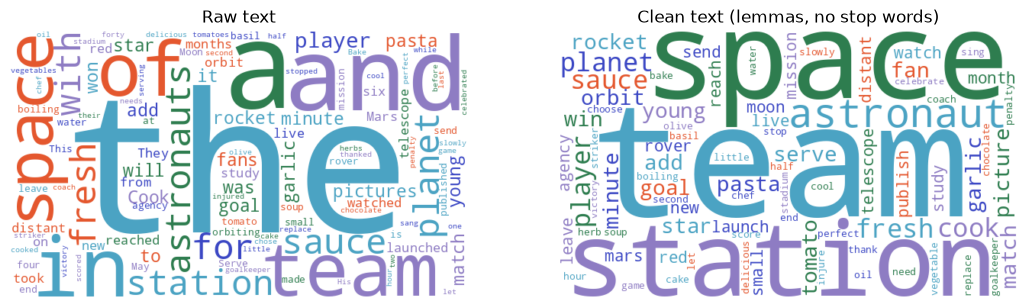

In [ ]:
course_colors = ListedColormap(["#3B47C4", "#E4572E", "#2E7D4F", "#8E7CC3", "#4BA3C3"])

def show_cloud(text, title, ax, stopwords=None):
    cloud = WordCloud(width=600, height=350, background_color="white", stopwords=stopwords,
                      colormap=course_colors, random_state=0).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
show_cloud(" ".join(corpus["text"]), "Raw text", axes[0], stopwords=set())
show_cloud(" ".join(corpus["clean"]), "Clean text (lemmas, no stop words)", axes[1])
plt.show()

**What this shows:** on the raw text, "the", "and", "of" and "in" are the biggest words, and they tell nothing about the corpus. On the clean text, the subjects appear: space, station, team, astronaut, planet, sauce. The lemmatizer also helps: "astronaut" and "astronauts" now count as one word.

## Summary 📝

* `spacy.load("en_core_web_sm")` loads a language model; `nlp(text)` returns a `Doc` made of tokens with `text`, `lemma_`, `pos_`, `is_stop`, `is_alpha`…
* A cleaning function keeps the lemmas of the useful tokens; `nlp.pipe` processes a whole corpus.
* `CountVectorizer` and `TfidfVectorizer` return a **sparse** document-term matrix; `get_feature_names_out()` gives the column names.
* Their options do part of the cleaning: `stop_words`, `min_df` (rare words), `max_df` (words common to all documents), `ngram_range` (n-grams).
* The cosine similarity between TF-IDF vectors finds the documents that talk about the same things, without any label.
* A word cloud is a nice picture for communication, not an analysis.

## Resources 📚

* [spaCy 101](https://spacy.io/usage/spacy-101): the main concepts of spaCy
* [`TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) in the scikit-learn documentation